# Báo cáo kết quả thí nghiệm Baseline

In [4]:
import json
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import confusion_matrix

In [2]:
import sys
from pathlib import Path

SHARED_FOLDER_NAME = 'data-poisoning-shared'
DRIVE_MOUNT = '/content/drive'

# 1. Mount Google Drive
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount(DRIVE_MOUNT)
elif not Path(DRIVE_MOUNT).is_dir():
    raise RuntimeError('Không tìm thấy Google Drive.')

# 2. Tìm thư mục dùng chung
_candidates = [
    Path(DRIVE_MOUNT) / 'MyDrive' / SHARED_FOLDER_NAME,
    Path(DRIVE_MOUNT) / 'Shareddrives' / SHARED_FOLDER_NAME,
]

_candidates.extend(
    sorted(Path(DRIVE_MOUNT, 'Shareddrives').glob(f'*/{SHARED_FOLDER_NAME}'))
)

DRIVE_ROOT = next((p for p in _candidates if p.is_dir()), None)

if DRIVE_ROOT is None:
    raise FileNotFoundError(
        f'Không tìm thấy thư mục {SHARED_FOLDER_NAME} trong Google Drive.'
    )

# 3. Trỏ đến thư mục kết quả Baseline
BASELINE_RESULTS = DRIVE_ROOT / 'results' / 'baseline'

if not BASELINE_RESULTS.is_dir():
    raise FileNotFoundError(
        f'Không tìm thấy thư mục kết quả Baseline: {BASELINE_RESULTS}'
    )

# 4. Hiển thị dữ liệu
print(f'Drive root       : {DRIVE_ROOT}')
print(f'Baseline results: {BASELINE_RESULTS}')

print('\nCác file hiện có:')
for path in sorted(BASELINE_RESULTS.rglob('*')):
    if path.is_file():
        print(f'  {path.relative_to(BASELINE_RESULTS)}')

print('\nĐã kết nối dữ liệu Baseline thành công.')

Mounted at /content/drive
Drive root       : /content/drive/MyDrive/data-poisoning-shared
Baseline results: /content/drive/MyDrive/data-poisoning-shared/results/baseline

Các file hiện có:
  analysis/baseline_seed_results.csv
  analysis/baseline_summary.csv
  analysis/per_class_f1.png
  analysis/per_class_seed_42.csv
  analysis/per_class_seed_43.csv
  analysis/per_class_seed_44.csv
  analysis/per_class_summary.csv
  confirm/seed_42/confusion_matrix.png
  confirm/seed_42/metrics.json
  confirm/seed_42/predictions.csv
  confirm/seed_43/confusion_matrix.png
  confirm/seed_43/metrics.json
  confirm/seed_43/predictions.csv
  confirm/seed_44/confusion_matrix.png
  confirm/seed_44/metrics.json
  confirm/seed_44/predictions.csv
  sweep/seed_42/confusion_matrix.png
  sweep/seed_42/metrics.json
  sweep/seed_42/predictions.csv

Đã kết nối dữ liệu Baseline thành công.


In [6]:
# General configuration
FIGURE_DPI = 120
FIGURE_SIZE = (12, 6)

METRIC_ORDER = [
    'accuracy',
    'precision',
    'recall',
    'f1_score'
]

METRIC_LABELS = {
    'accuracy': 'Accuracy',
    'precision': 'Precision',
    'recall': 'Recall',
    'f1_score': 'F1-score'
}

SEED_COLORS = {
    42: '#4C78A8',
    43: '#F58518',
    44: '#54A24B'
}

plt.rcParams.update({
    'figure.dpi': FIGURE_DPI,
    'axes.titlesize': 14,
    'axes.labelsize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 10,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# Kiểm tra các cột cần thiết
required_columns = {
    'baseline_seed': [
        'seed', 'accuracy', 'precision', 'recall', 'f1_score'
    ],
    'baseline_summary': [
        'metric', 'mean', 'std', 'mean_std'
    ],
    'per_class_summary': [
        'class_id', 'class_name',
        'mean_precision', 'mean_recall',
        'mean_f1_score', 'mean_support'
    ]
}

assert set(required_columns['baseline_seed']).issubset(
    baseline_seed_df.columns
)

assert set(required_columns['baseline_summary']).issubset(
    baseline_summary_df.columns
)

assert set(required_columns['per_class_summary']).issubset(
    per_class_summary_df.columns
)

print('Data validation: OK')

Data validation: OK


In [5]:
# Đường dẫn đã được khai báo ở cell Mount Drive
ANALYSIS_DIR = BASELINE_RESULTS / 'analysis'
CONFIRM_DIR = BASELINE_RESULTS / 'confirm'

# Đọc kết quả tổng hợp
baseline_seed_df = pd.read_csv(
    ANALYSIS_DIR / 'baseline_seed_results.csv'
)

baseline_summary_df = pd.read_csv(
    ANALYSIS_DIR / 'baseline_summary.csv'
)

per_class_summary_df = pd.read_csv(
    ANALYSIS_DIR / 'per_class_summary.csv'
)

# Đọc kết quả từng seed
SEEDS = [42, 43, 44]

per_class_seed_dfs = {}

for seed in SEEDS:
    path = ANALYSIS_DIR / f'per_class_seed_{seed}.csv'

    per_class_seed_dfs[seed] = pd.read_csv(path)

# Đọc predictions và metrics
predictions = {}
metrics = {}

for seed in SEEDS:
    seed_dir = CONFIRM_DIR / f'seed_{seed}'

    predictions[seed] = pd.read_csv(
        seed_dir / 'predictions.csv'
    )

    with open(seed_dir / 'metrics.json', 'r') as f:
        metrics[seed] = json.load(f)

# Chuẩn hóa thứ tự class
per_class_summary_df = per_class_summary_df.sort_values(
    'class_id'
).reset_index(drop=True)

print('Đã load dữ liệu Baseline thành công.')

print('Baseline seed results:', baseline_seed_df.shape)
print('Baseline summary:', baseline_summary_df.shape)
print('Per-class summary:', per_class_summary_df.shape)

for seed in SEEDS:
    print(
        f'Seed {seed}: '
        f'{len(predictions[seed])} predictions'
    )

Đã load dữ liệu Baseline thành công.
Baseline seed results: (3, 5)
Baseline summary: (4, 4)
Per-class summary: (38, 9)
Seed 42: 10876 predictions
Seed 43: 10876 predictions
Seed 44: 10876 predictions


## 1. Tổng quan hiệu suất mô hình

### 1.1. Performance Metrics Comparison

Mục tiêu: So sánh Accuracy, Precision, Recall và F1-score giữa 3 lần chạy.

Dữ liệu sử dụng: `baseline_seed_results.csv`.

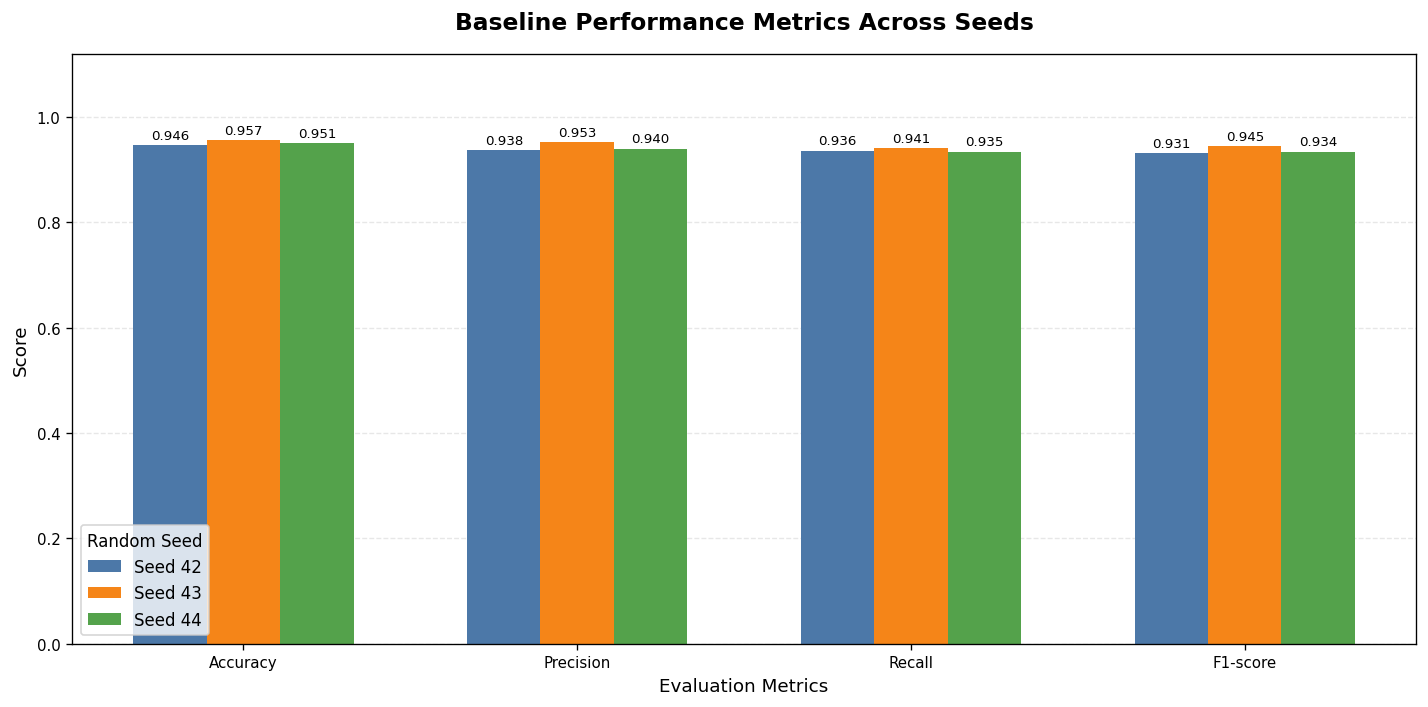

In [7]:
df = baseline_seed_df.copy()

x = np.arange(len(METRIC_ORDER))
bar_width = 0.22

fig, ax = plt.subplots(figsize=(12, 6))

for i, seed in enumerate(SEEDS):
    seed_data = df[df['seed'] == seed].iloc[0]

    values = [
        seed_data[metric]
        for metric in METRIC_ORDER
    ]

    offset = (i - (len(SEEDS) - 1) / 2) * bar_width

    bars = ax.bar(
        x + offset,
        values,
        bar_width,
        label=f'Seed {seed}',
        color=SEED_COLORS[seed]
    )

    ax.bar_label(
        bars,
        fmt='%.3f',
        fontsize=8,
        padding=2
    )

ax.set_title(
    'Baseline Performance Metrics Across Seeds',
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Evaluation Metrics')
ax.set_ylabel('Score')

ax.set_xticks(x)
ax.set_xticklabels([
    METRIC_LABELS[m] for m in METRIC_ORDER
])

ax.set_ylim(0, 1.12)
ax.legend(title='Random Seed')

ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 1.2. Mean Performance ± Standard Deviation
Mục tiêu: Thể hiện hiệu suất trung bình và độ biến động giữa các lần chạy.

Dữ liệu sử dụng: `baseline_summary.csv`.

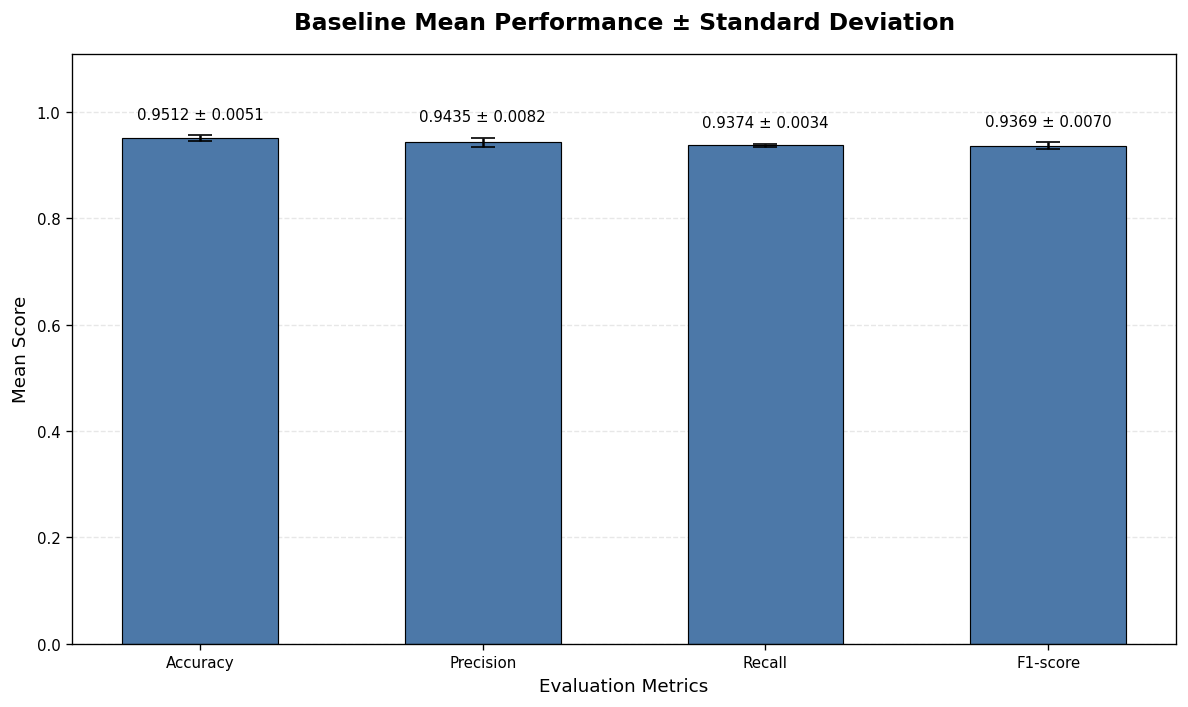

In [8]:
summary = baseline_summary_df.set_index('metric')

means = [
    summary.loc[m, 'mean']
    for m in METRIC_ORDER
]

stds = [
    summary.loc[m, 'std']
    for m in METRIC_ORDER
]

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(METRIC_ORDER))

bars = ax.bar(
    x,
    means,
    yerr=stds,
    capsize=7,
    width=0.55,
    color='#4C78A8',
    edgecolor='black',
    linewidth=0.7
)

ax.bar_label(
    bars,
    labels=[
        f'{mean:.4f} ± {std:.4f}'
        for mean, std in zip(means, stds)
    ],
    padding=8,
    fontsize=9
)

ax.set_title(
    'Baseline Mean Performance ± Standard Deviation',
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Evaluation Metrics')
ax.set_ylabel('Mean Score')

ax.set_xticks(x)
ax.set_xticklabels([
    METRIC_LABELS[m] for m in METRIC_ORDER
])

ax.set_ylim(
    0,
    min(1.2, max(means) + max(stds) + 0.15)
)

ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 2. Per-class Performance

### 2.1. Per-class F1-score

Mục tiêu: Xác định class nào có hiệu suất phân loại tốt và kém nhất.

Dữ liệu sử dụng: `per_class_summary.csv`.

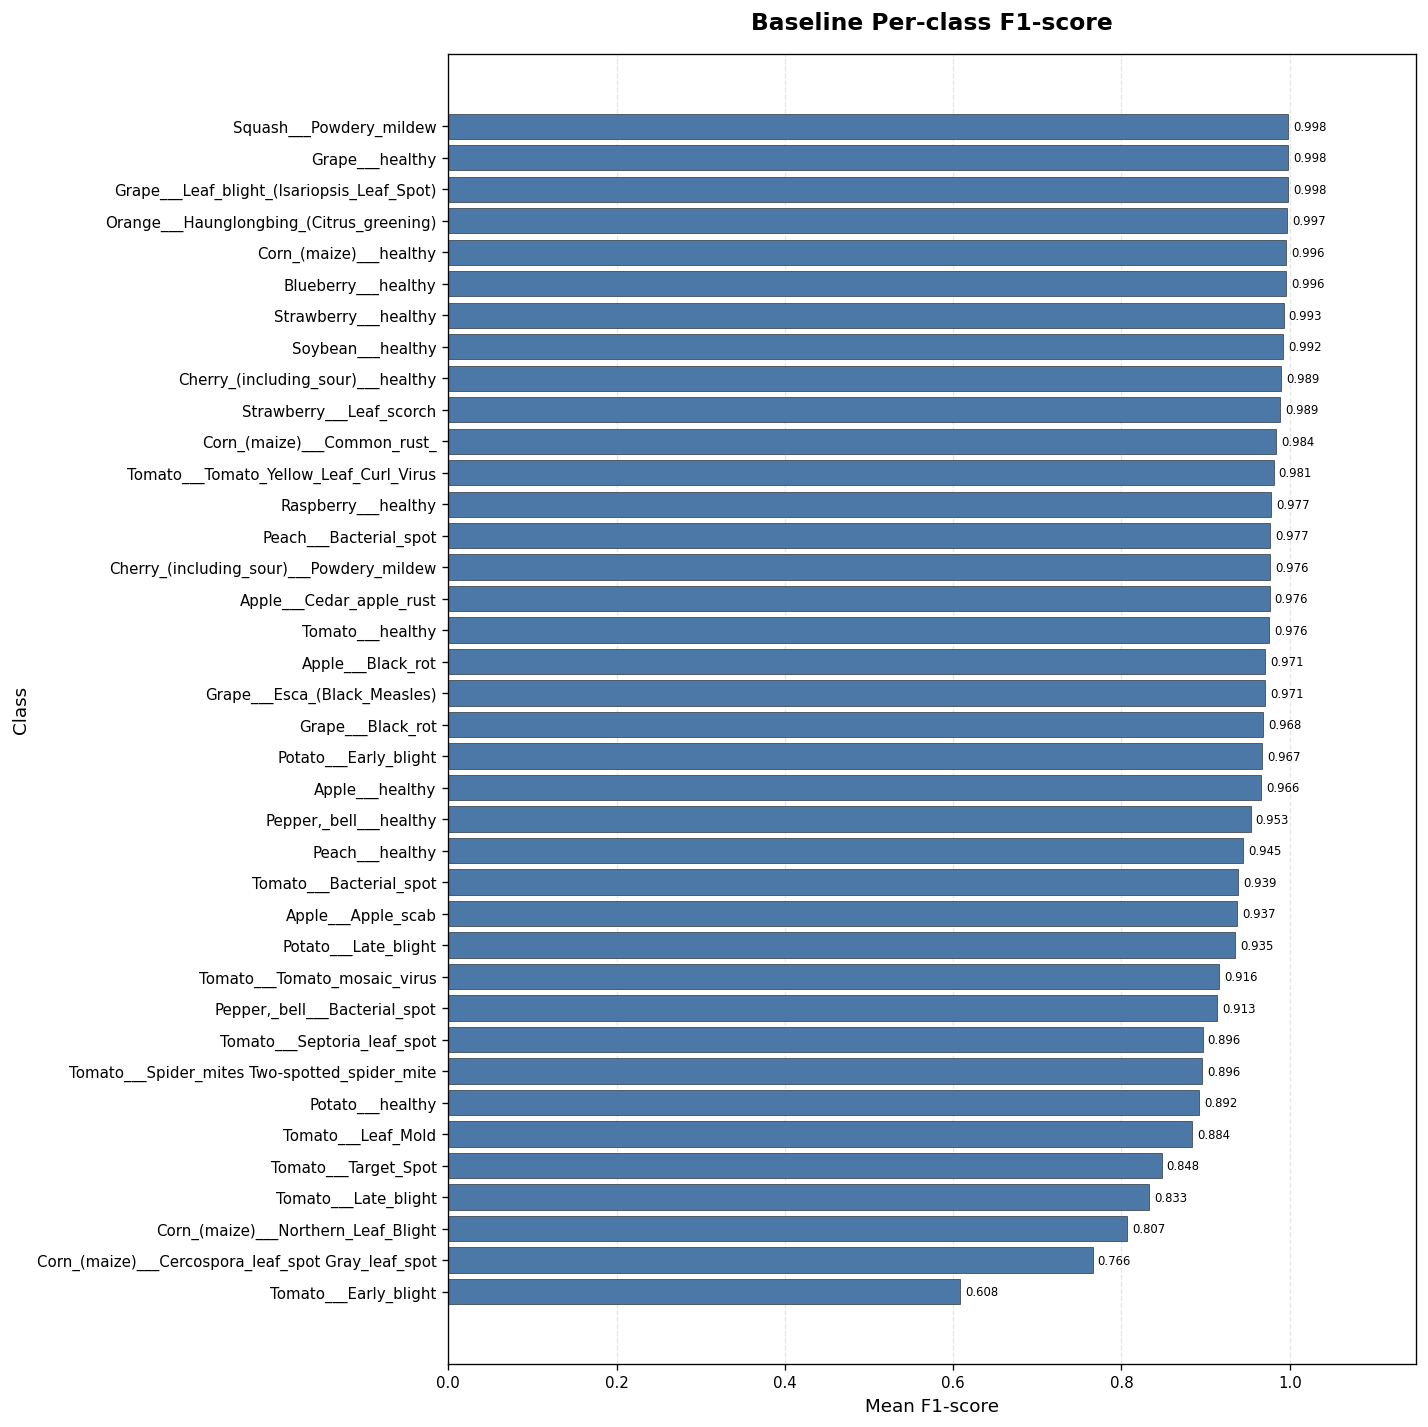

In [9]:
df = per_class_summary_df.sort_values(
    'mean_f1_score',
    ascending=True
).copy()

fig, ax = plt.subplots(figsize=(12, 12))

bars = ax.barh(
    df['class_name'],
    df['mean_f1_score'],
    color='#4C78A8',
    edgecolor='black',
    linewidth=0.3
)

ax.bar_label(
    bars,
    fmt='%.3f',
    padding=3,
    fontsize=7
)

ax.set_title(
    'Baseline Per-class F1-score',
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Mean F1-score')
ax.set_ylabel('Class')

ax.set_xlim(0, 1.15)

ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 2.2. Per-class Precision & Recall
Mục tiêu: So sánh khả năng nhận diện đúng và khả năng tìm đủ mẫu của từng class.

Dữ liệu sử dụng: `per_class_summary.csv`.

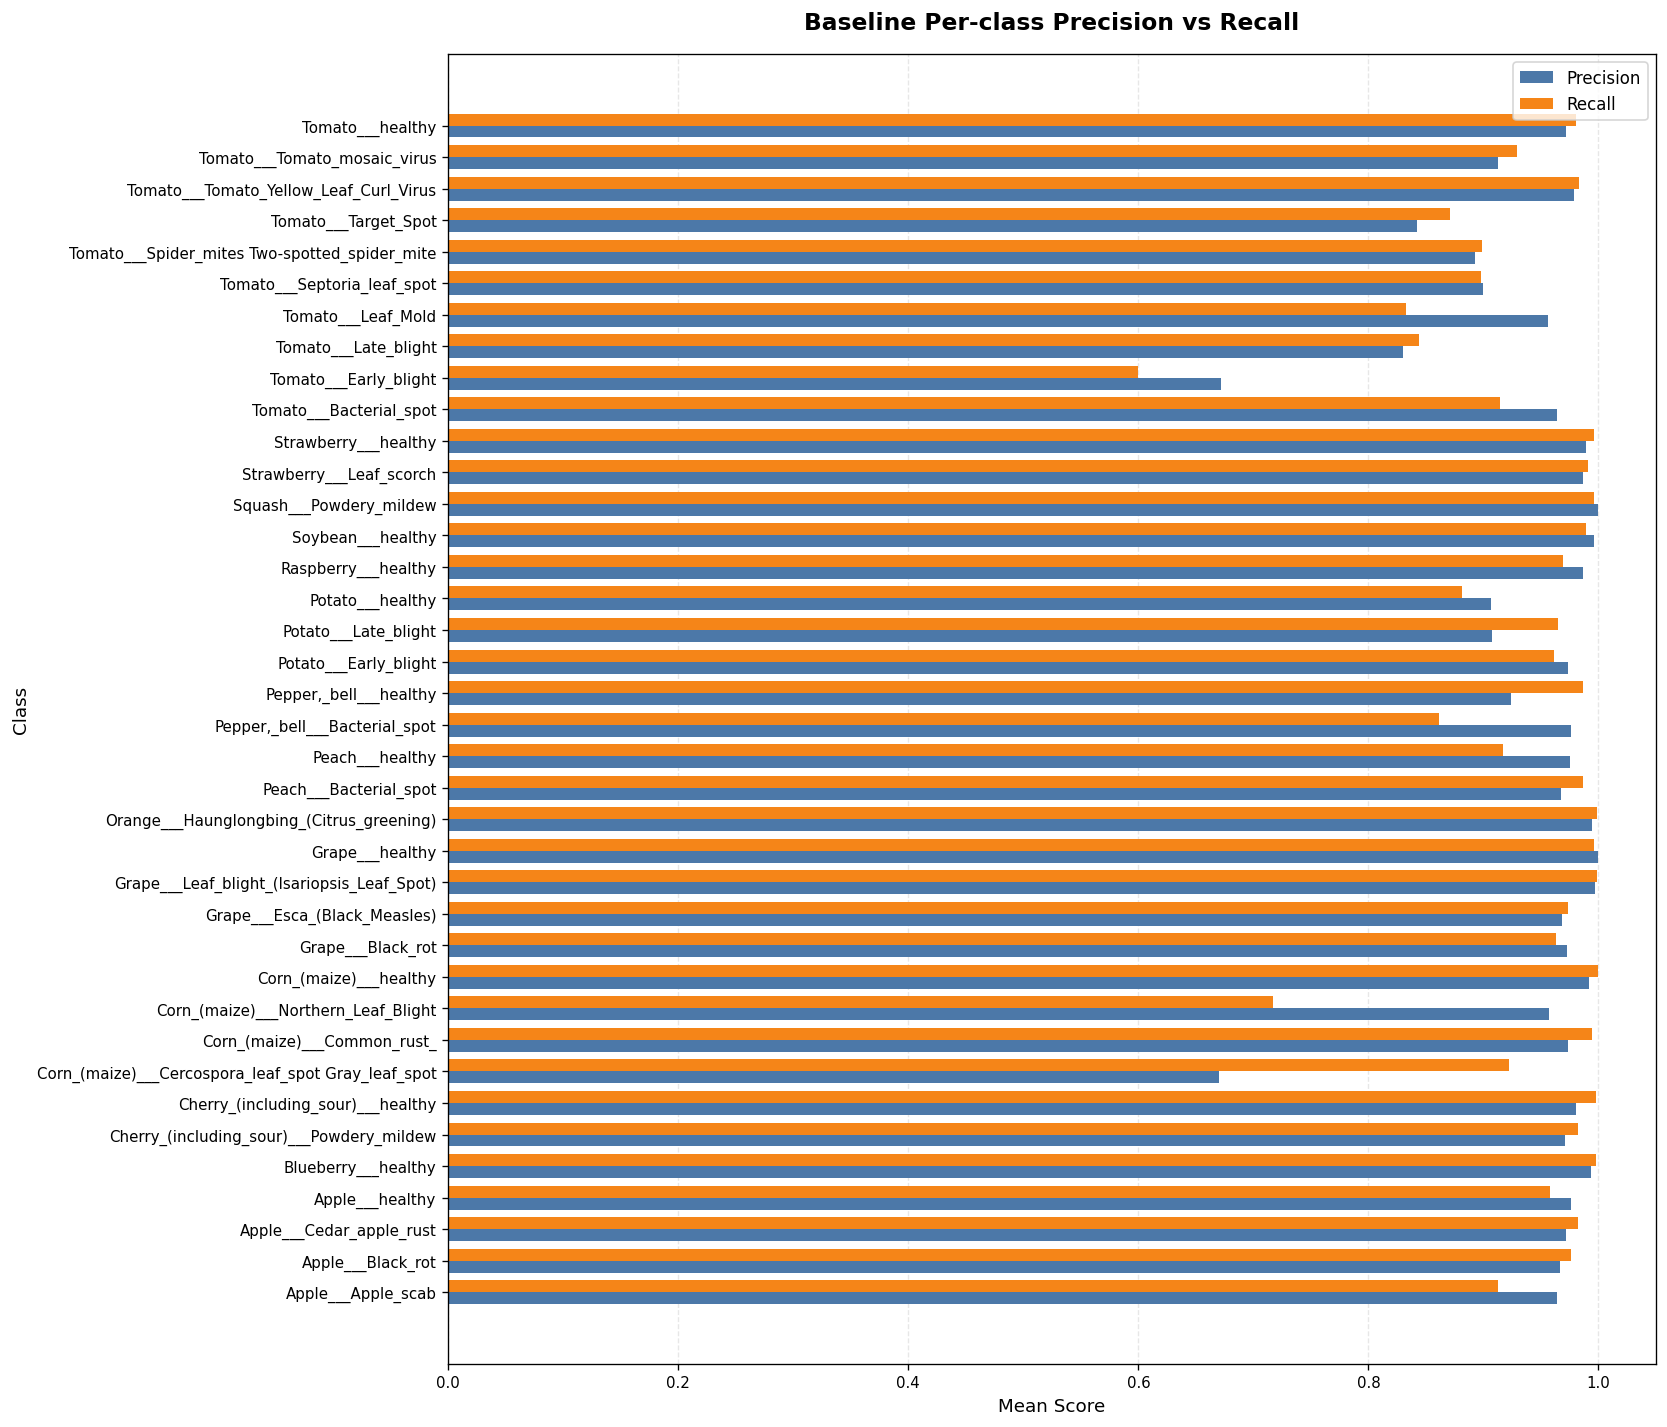

In [10]:
df = per_class_summary_df.sort_values(
    'class_id'
).copy()

y = np.arange(len(df))
bar_width = 0.38

fig, ax = plt.subplots(figsize=(14, 12))

bars_precision = ax.barh(
    y - bar_width / 2,
    df['mean_precision'],
    bar_width,
    label='Precision',
    color='#4C78A8'
)

bars_recall = ax.barh(
    y + bar_width / 2,
    df['mean_recall'],
    bar_width,
    label='Recall',
    color='#F58518'
)

ax.set_yticks(y)
ax.set_yticklabels(df['class_name'])

ax.set_title(
    'Baseline Per-class Precision vs Recall',
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Mean Score')
ax.set_ylabel('Class')

ax.set_xlim(0, 1.05)

ax.legend()
ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 3. Display Original Confusion Matrices

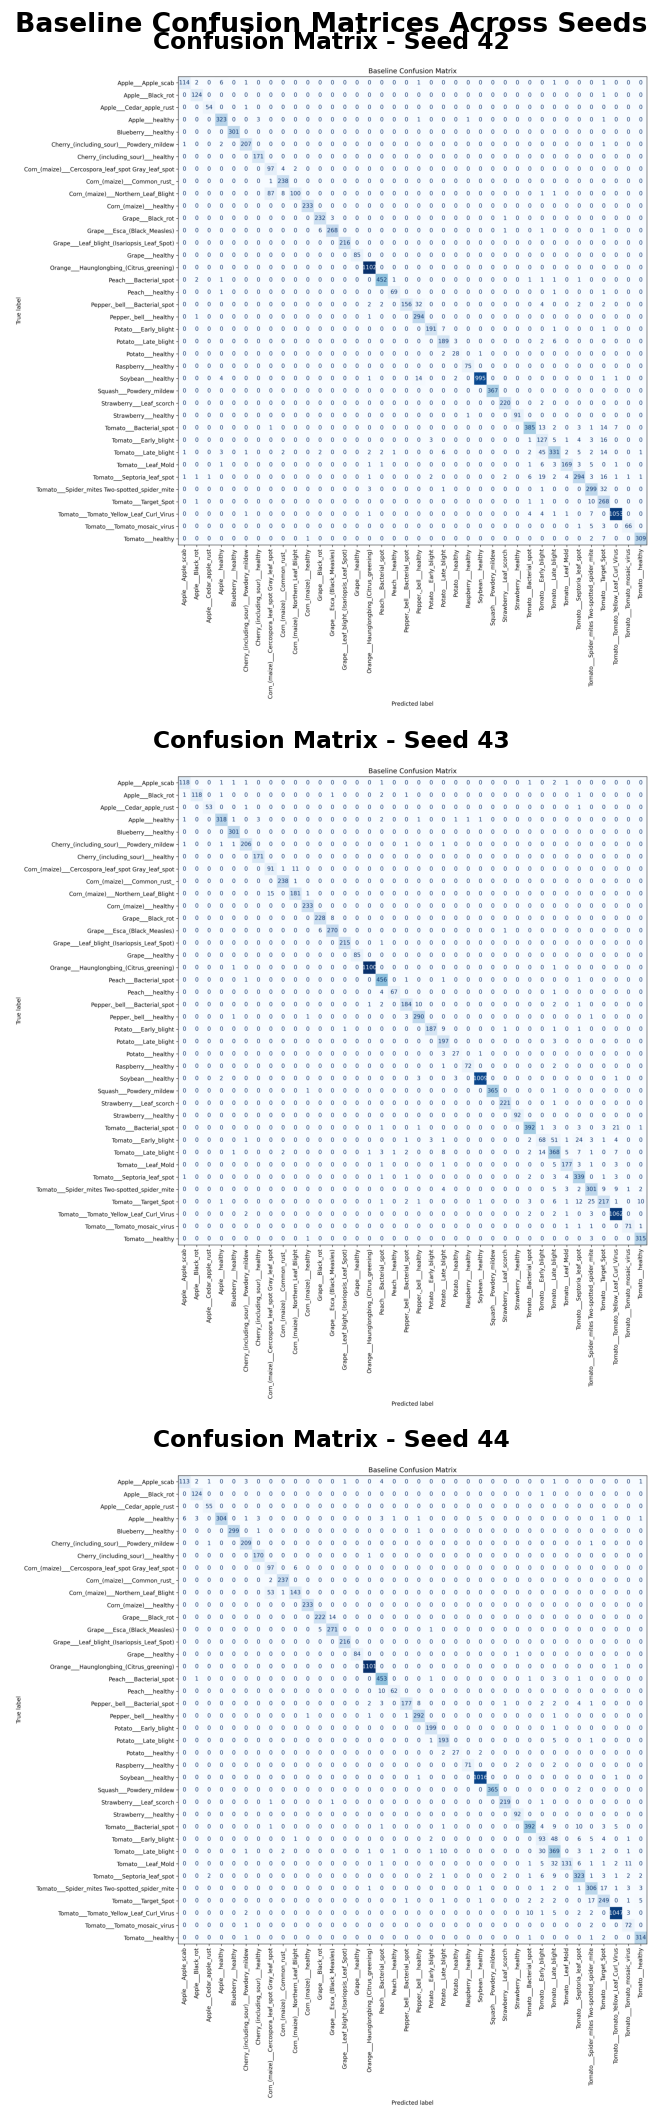

In [13]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    len(SEEDS),
    1,
    figsize=(12, 18)
)

for ax, seed in zip(axes, SEEDS):

    image_path = (
        CONFIRM_DIR
        / f'seed_{seed}'
        / 'confusion_matrix.png'
    )

    if not image_path.is_file():
        ax.set_title(f'Seed {seed} - Image Not Found')
        ax.axis('off')
        continue

    image = Image.open(image_path)

    ax.imshow(image)
    ax.set_title(
        f'Confusion Matrix - Seed {seed}',
        fontweight='bold',
        pad=10
    )
    ax.axis('off')

fig.suptitle(
    'Baseline Confusion Matrices Across Seeds',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()